In [1]:
# Agentic AI & Multi-Agent Network Operations

In [2]:
from __future__ import annotations

import hashlib
import operator
import importlib.metadata as metadata
import json
import math
import os
import platform
import re
import sqlite3
import tempfile
import time
import uuid
from dataclasses import dataclass
from datetime import datetime, timedelta, timezone
from pathlib import Path
from typing import Annotated, Any, Callable, Literal, TypedDict

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from pydantic import BaseModel, ConfigDict, Field, ValidationError, model_validator
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 120)
RANDOM_STATE = 42

print("Python:", platform.python_version())
print("Platform:", platform.platform())

Python: 3.12.13
Platform: macOS-27.0.1-arm64-arm-64bit


In [3]:
def show_langgraph_figure(compiled_graph, title: str) -> None:
    '''Display a compiled LangGraph as a Mermaid PNG, with a safe text fallback.'''
    print(f"\n{title}")
    try:
        # User-requested visualization pattern:
        display(Image(compiled_graph.get_graph().draw_mermaid_png()))
    except Exception as exc:
        print(f"PNG rendering unavailable ({type(exc).__name__}). Mermaid source follows:")
        print(compiled_graph.get_graph().draw_mermaid())

In [4]:
EXPECTED = {
    "numpy": "2.5.2",
    "pandas": "3.0.5",
    "scikit-learn": "1.9.0",
    "pydantic": "2.13.4",
    "networkx": "3.6.1",
    "openai": "3.3.1",
    "openai-agents": "0.22.0",
    "langgraph": "1.2.11",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.3.0",
}
installed = {name: metadata.version(name) for name in EXPECTED}
version_check = pd.DataFrame(
    [
        {
            "package": name,
            "expected": expected,
            "installed": installed[name],
            "match": installed[name] == expected,
        }
        for name, expected in EXPECTED.items()
    ]
)
display(version_check)
assert tuple(map(int, platform.python_version_tuple()[:2])) >= (3, 12)
assert version_check["match"].all(), "Install the exact Session 4 requirements before continuing."
print("✓ Runtime matches the tested package set")

,package,expected,installed,match
0,numpy,2.5.2,2.5.2,True
1,pandas,3.0.5,3.0.5,True
2,scikit-learn,1.9.0,1.9.0,True
3,pydantic,2.13.4,2.13.4,True
4,networkx,3.6.1,3.6.1,True
5,openai,3.3.1,3.3.1,True
6,openai-agents,0.22.0,0.22.0,True
7,langgraph,1.2.11,1.2.11,True
8,nbformat,5.11.1,5.11.1,True
9,nbclient,0.11.0,0.11.0,True


✓ Runtime matches the tested package set


In [5]:
def locate_artifact(filename: str) -> Path:
    candidates = [
        Path.cwd() / filename,
        Path.cwd() / "outputs" / filename,
        Path.cwd().parent / "outputs" / filename,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(f"Could not find {filename}. Checked: {candidates}")

CORPUS_PATH = locate_artifact("session3_walmart_network_corpus.jsonl")
MANIFEST_PATH = locate_artifact("session3_source_manifest.json")
records = [json.loads(line) for line in CORPUS_PATH.read_text().splitlines() if line.strip()]
manifest = json.loads(MANIFEST_PATH.read_text())

assert hashlib.sha256(CORPUS_PATH.read_bytes()).hexdigest() == manifest["corpus_sha256"]
assert len(records) == manifest["record_count"]
print(manifest["provenance_statement"])
print(f"✓ Loaded {len(records)} verified public records")

All operational facts and examples are sourced from public Walmart Global Tech or Walmart-originated L3AF project materials. No internal Walmart runbook, configuration, incident, topology, monitoring record, credential, or production state is claimed or fabricated.
✓ Loaded 81 verified public records


In [6]:
corpus_df = pd.DataFrame(records)
display(
    corpus_df.groupby("source_type", as_index=False)
    .agg(records=("doc_id", "count"), example=("title", "first"))
    .sort_values("records", ascending=False)
)

search_texts = (corpus_df["title"] + " " + corpus_df["content"]).tolist()
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
corpus_matrix = vectorizer.fit_transform(search_texts)

def search_corpus(query: str, top_k: int = 5, source_types: set[str] | None = None) -> list[dict[str, Any]]:
    if not query.strip():
        raise ValueError("query must not be empty")
    scores = cosine_similarity(vectorizer.transform([query]), corpus_matrix).ravel()
    mask = np.ones(len(corpus_df), dtype=bool)
    if source_types:
        mask = corpus_df["source_type"].isin(source_types).to_numpy()
    candidates = np.where(mask)[0]
    ranked = candidates[np.argsort(scores[candidates])[::-1]][:top_k]
    return [
        {
            **corpus_df.iloc[i].to_dict(),
            "score": float(scores[i]),
        }
        for i in ranked
    ]

display(pd.DataFrame(search_corpus("BPFRunning metric loading error", 3))[["doc_id", "score", "title", "source_url"]])

,source_type,records,example
4,historical_issue,37,L3AFD issue #754: Build failure on Cilium eBPF package upgrade
3,configuration_standard,12,configdoc: L3AFD Config Options Documentation
2,configuration_repository,10,l3afd sample configuration: [l3afd]
9,project_readme,9,README: L3AFD: Lightweight eBPF Daemon
6,operational_runbook,5,graceful-restart-guide: Prerequisites
8,production_deployment_guide,3,prod-deploy-guide: Installing l3afd
7,package_repository_guide,2,README: eBPF Package Repository
0,api_specification,1,l3afd REST API operation inventory
1,change_records,1,L3AFD recent public commit history
5,official_walmart_global_tech_article,1,Walmart Global Tech: published network scale and open-source context


,doc_id,score,title,source_url
0,l3afd-issue-698,0.295954,L3AFD issue #698: l3afd_BPFRunning metric reports true incase of ebpf_program loading error,https://github.com/l3af-project/l3afd/issues/698
1,l3afd-issue-523,0.129092,L3AFD issue #523: Add metrics to count ebpf program loading failure errors,https://github.com/l3af-project/l3afd/issues/523
2,l3afd-issue-637,0.080799,L3AFD issue #637: Remove stale metric reporting on eBPF program unload,https://github.com/l3af-project/l3afd/issues/637


## LangGraph from first principles

LangGraph is an orchestration framework for long-running, stateful workflows and agents. It does not magically make an LLM autonomous. It gives engineers explicit control over **what can happen next**.

Think of a network troubleshooting workflow as a controlled packet journey:

| LangGraph concept | Plain meaning | Infrastructure analogy |
|---|---|---|
| State | Shared typed record carried through the workflow | Incident record containing evidence, status and approvals |
| Node | A Python function that reads state and returns updates | Monitoring query, configuration check or RCA step |
| Edge | An allowed transition between nodes | Runbook transition from evidence collection to validation |
| Conditional edge | Runtime routing decision | If severity is critical, escalate; otherwise continue diagnosis |
| Loop | Revisit a node until a stopping condition holds | Poll telemetry until enough samples arrive or the budget expires |
| Checkpointer | Saves thread-scoped state after steps | Incident checkpoint used to resume after a pause or failure |
| Interrupt | Pauses execution for external input | Human approval before a controlled action |
| Command | Resumes or redirects execution | Approval response that continues the saved workflow |

The engineering sequence is always the same:

**Define state → write small nodes → connect edges → compile → invoke with input → inspect final state**

Why use a graph instead of a large `while` loop? The graph makes legal transitions, branches, cycles, checkpoints and human gates visible and testable. Business policy still belongs in deterministic code; the model may assist with semantic decisions inside those boundaries.

### Example A — Linear shared-state flow

A linear graph is the easiest mental model: intake receives an incident, normalization creates a consistent representation, and summary produces the handoff. Every node receives the same state schema and returns only its updates.

In [ ]:
# Imagine Walmart's Network Operations Center (NOC) receives hundreds of network incidents every day.

# For example:
#     "  DC-07 inventory API is intermittently unreachable  "

# Before an AI agent can investigate this issue, the system must accept the incident, clean the text, and create a standardized summary.

# This code builds a simple, automated workflow using LangGraph, where three steps execute one after another.

,input,normalized,summary,node_outputs
0,DC-07 inventory API is intermittently unreachable,dc-07 inventory api is intermittently unreachable,Network incident received: dc-07 inventory api is intermittently unreachable,intake accepted → incident normalized → summary created
1,STORE-1842 access point reports high channel utilization,store-1842 access point reports high channel utilization,Network incident received: store-1842 access point reports high channel utilization,intake accepted → incident normalized → summary created
2,Cloud load balancer health checks are timing out,cloud load balancer health checks are timing out,Network incident received: cloud load balancer health checks are timing out,intake accepted → incident normalized → summary created



Figure A — Linear intake workflow


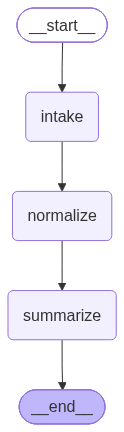

In [ ]:
# Think of it as a shared digital incident form that travels through all three stages of our workflow.
class LinearState(TypedDict):
    incident: str # Stores the original network incident.
    normalized: str # Stores the cleaned incident text.
    summary: str # Stores the final incident summary.
    events: Annotated[list[str], operator.add] # Stores the history of steps completed by the workflow.
    # Annotated[list[str], operator.add]
    # Normally, returning a new value for a state key replaces the existing value.
    # However, we want to keep adding events instead of overwriting previous events.

# How the events list grows
# After intake:
#     ["intake accepted"]
# After normalization:
#     ["intake accepted", "incident normalized"]
# After summarization:
#     ["intake accepted", "incident normalized", "summary created"]
# operator.add tells LangGraph to concatenate the new list with the existing list.

def linear_intake(state: LinearState) -> dict: # "  DC-07 inventory API is intermittently unreachable  "
    return {"events": ["intake accepted"]} # return: {"events": ["intake accepted"]}

# Network incident descriptions can arrive with inconsistent capitalization and unnecessary spaces. We want a standardized format.
def linear_normalize(state: LinearState) -> dict:
    normalized = re.sub(r"\s+", " ", state["incident"].strip()).lower()
    return {"normalized": normalized, "events": ["incident normalized"]}
# Original network incident  
#     DC-07   inventory API is intermittently unreachable  
# NORMALIZED OUTPUT
#     dc-07 inventory api is intermittently unreachable
# Normalization makes incident text consistent. It does not diagnose the root cause.

def linear_summarize(state: LinearState) -> dict:
    return {
        "summary": f"Network incident received: {state['normalized']}",
        "events": ["summary created"],
    }

linear_builder = StateGraph(LinearState)
linear_builder.add_node("intake", linear_intake)
linear_builder.add_node("normalize", linear_normalize)
linear_builder.add_node("summarize", linear_summarize)
linear_builder.add_edge(START, "intake")
linear_builder.add_edge("intake", "normalize")
linear_builder.add_edge("normalize", "summarize")
linear_builder.add_edge("summarize", END)
linear_graph = linear_builder.compile()

linear_examples = [
    "  DC-07 inventory API is intermittently unreachable  ",
    "STORE-1842 access point reports high channel utilization",
    "Cloud load balancer health checks are timing out",
]
linear_results = []
for example in linear_examples: # example="  DC-07 inventory API is intermittently unreachable  "
    result = linear_graph.invoke({
        "incident":example, "normalized":"", "summary":"", "events":[],
    })
    linear_results.append({
        "input":example.strip(), "normalized":result["normalized"],
        "summary":result["summary"], "node_outputs":" → ".join(result["events"]),
    })

display(pd.DataFrame(linear_results))
show_langgraph_figure(linear_graph, "Figure A — Linear intake workflow")
assert all(row["node_outputs"].endswith("summary created") for row in linear_results)

### Example B — Conditional branch

A branch represents an explicit operating decision. Here the classifier is deterministic and auditable: critical incidents follow an urgent path; other incidents follow the standard path. In production the model may propose severity, but policy validates it before routing.

In [ ]:
# Consider two situations:
# - SEV1: A critical network failure is affecting important business applications. We need immediate escalation.
# - SEV3: A lower-severity network issue is reported. We can schedule routine diagnostics.

# We want our LangGraph workflow to automatically select the appropriate response based on incident severity.
# This introduces an important concept: Conditional Branching.

,severity,route,response,events
0,SEV1,urgent,Open incident bridge and page the on-call lead.,classified as urgent → urgent path
1,SEV2,standard,Queue bounded diagnostic collection.,classified as standard → standard path
2,SEV3,standard,Queue bounded diagnostic collection.,classified as standard → standard path



Figure B — Conditional severity branch


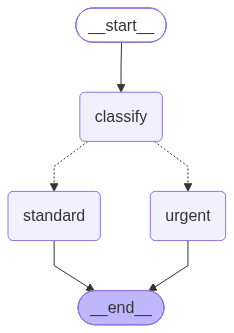

In [8]:
class BranchState(TypedDict):
    severity: str
    route: str
    response: str
    events: Annotated[list[str], operator.add]

def classify_severity(state: BranchState) -> dict:
    route = "urgent" if state["severity"].upper() in {"SEV0", "SEV1"} else "standard"
    return {"route": route, "events": [f"classified as {route}"]}

def urgent_path(state: BranchState) -> dict:
    return {"response": "Open incident bridge and page the on-call lead.", "events": ["urgent path"]}

def standard_path(state: BranchState) -> dict:
    return {"response": "Queue bounded diagnostic collection.", "events": ["standard path"]}

branch_builder = StateGraph(BranchState)
branch_builder.add_node("classify", classify_severity)
branch_builder.add_node("urgent", urgent_path)
branch_builder.add_node("standard", standard_path)
branch_builder.add_edge(START, "classify")
branch_builder.add_conditional_edges("classify", lambda s: s["route"], {"urgent":"urgent", "standard":"standard"})
branch_builder.add_edge("urgent", END)
branch_builder.add_edge("standard", END)
branch_graph = branch_builder.compile()

branch_results = []
for severity in ["SEV1", "SEV2", "SEV3"]:
    result = branch_graph.invoke({"severity":severity, "route":"", "response":"", "events":[]})
    branch_results.append({"severity":severity, "route":result["route"],
                           "response":result["response"], "events":" → ".join(result["events"])})

display(pd.DataFrame(branch_results))
show_langgraph_figure(branch_graph, "Figure B — Conditional severity branch")
assert {row["route"] for row in branch_results} == {"urgent", "standard"}

### Example C — Bounded loop

Agents often need another observation. A safe loop has a measurable completion condition and a hard budget. This example collects at most three samples; it cannot poll forever.

In [ ]:
# Imagine Walmart's Network Operations Center (NOC) receives an incident:
#     "DC-07 inventory API is experiencing intermittent response delays."

# Before investigating the issue, the system needs to collect monitoring evidence.

# But collecting just one sample may not be sufficient to understand the problem.

# We want our workflow to:
# 1. Collect a monitoring sample.
# 2. Check whether enough samples have been collected.
# 3. If not, collect another sample.
# 4. Stop when three samples are available.
# 5. Alternatively, stop if the maximum permitted attempts have been reached.

# The key problem: How do we allow repeated execution without creating an infinite loop or wasting monitoring resources?

# That is exactly what this code demonstrates.

,max_attempts,actual_attempts,samples,enough_evidence,stop_reason
0,2,2,"[95, 90]",False,attempt budget exhausted
1,3,3,"[95, 90, 85]",True,three samples collected
2,5,3,"[95, 90, 85]",True,three samples collected



Figure C — Bounded evidence-collection loop


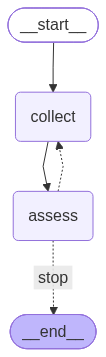

In [ ]:
class LoopState(TypedDict):
    attempts: int
    max_attempts: int
    samples: Annotated[list[int], operator.add]
    enough_evidence: bool
    stop_reason: str

# {"attempts":0, "max_attempts":max_attempts, "samples":[],
        #  "enough_evidence":False, "stop_reason":""}
def collect_sample(state: LoopState) -> dict:
    next_attempt = state["attempts"] + 1
    return {"attempts": next_attempt, "samples": [100 - 5 * next_attempt]}

# {"attempts":1, "max_attempts":max_attempts, "samples":[],
        #  "enough_evidence":False, "stop_reason":""}
def assess_samples(state: LoopState) -> dict:
    enough = len(state["samples"]) >= 3
    exhausted = state["attempts"] >= state["max_attempts"]
    reason = "three samples collected" if enough else ("attempt budget exhausted" if exhausted else "need another sample")
    return {"enough_evidence": enough, "stop_reason": reason}

def route_loop(state: LoopState) -> str:
    return "stop" if state["enough_evidence"] or state["attempts"] >= state["max_attempts"] else "collect"

loop_builder = StateGraph(LoopState)
loop_builder.add_node("collect", collect_sample)
loop_builder.add_node("assess", assess_samples)
loop_builder.add_edge(START, "collect")
loop_builder.add_edge("collect", "assess")
loop_builder.add_conditional_edges("assess", route_loop, {"collect":"collect", "stop":END})
loop_graph = loop_builder.compile()

loop_results = []
for max_attempts in [2, 3, 5]:
    result = loop_graph.invoke(
        {"attempts":0, "max_attempts":max_attempts, "samples":[],
         "enough_evidence":False, "stop_reason":""},
        config={"recursion_limit":20},
    )
    loop_results.append({"max_attempts":max_attempts, "actual_attempts":result["attempts"],
                         "samples":result["samples"], "enough_evidence":result["enough_evidence"],
                         "stop_reason":result["stop_reason"]})

display(pd.DataFrame(loop_results))
show_langgraph_figure(loop_graph, "Figure C — Bounded evidence-collection loop")
assert loop_results[0]["stop_reason"] == "attempt budget exhausted"
assert loop_results[1]["enough_evidence"] and loop_results[2]["actual_attempts"] == 3

### Example D — Human-in-the-loop interrupt and resume

LangGraph `interrupt()` pauses a node and stores the thread state through a checkpointer. The application displays the JSON-safe approval request. The same `thread_id` is then resumed with `Command(resume=...)`. Code before an interrupt can execute again after resumption, so side effects must occur only after approval and must be idempotent.

In [ ]:
# Now we are introducing a fourth important concept: Human-in-the-Loop (HITL) Approval.

# Imagine Walmart's Network Operations Center (NOC) has an AI agent that recommends the following action:
# "Restart a production edge router to investigate a connectivity issue."

# Should the AI agent automatically restart the router?

# No. Restarting production network equipment could interrupt business-critical services.

# We want our LangGraph workflow to:
# 1. Propose an action.
# 2. Pause execution and request human approval.
# 3. Preserve the workflow state while waiting.
# 4. Resume when a human decision is supplied.
# 5. Follow the approved or rejected path.
# 6. Record the final outcome.
# This is exactly what the code demonstrates.

# Important: The example simulates approval decisions and dry-run execution. It does not connect to real network equipment or perform actual changes.

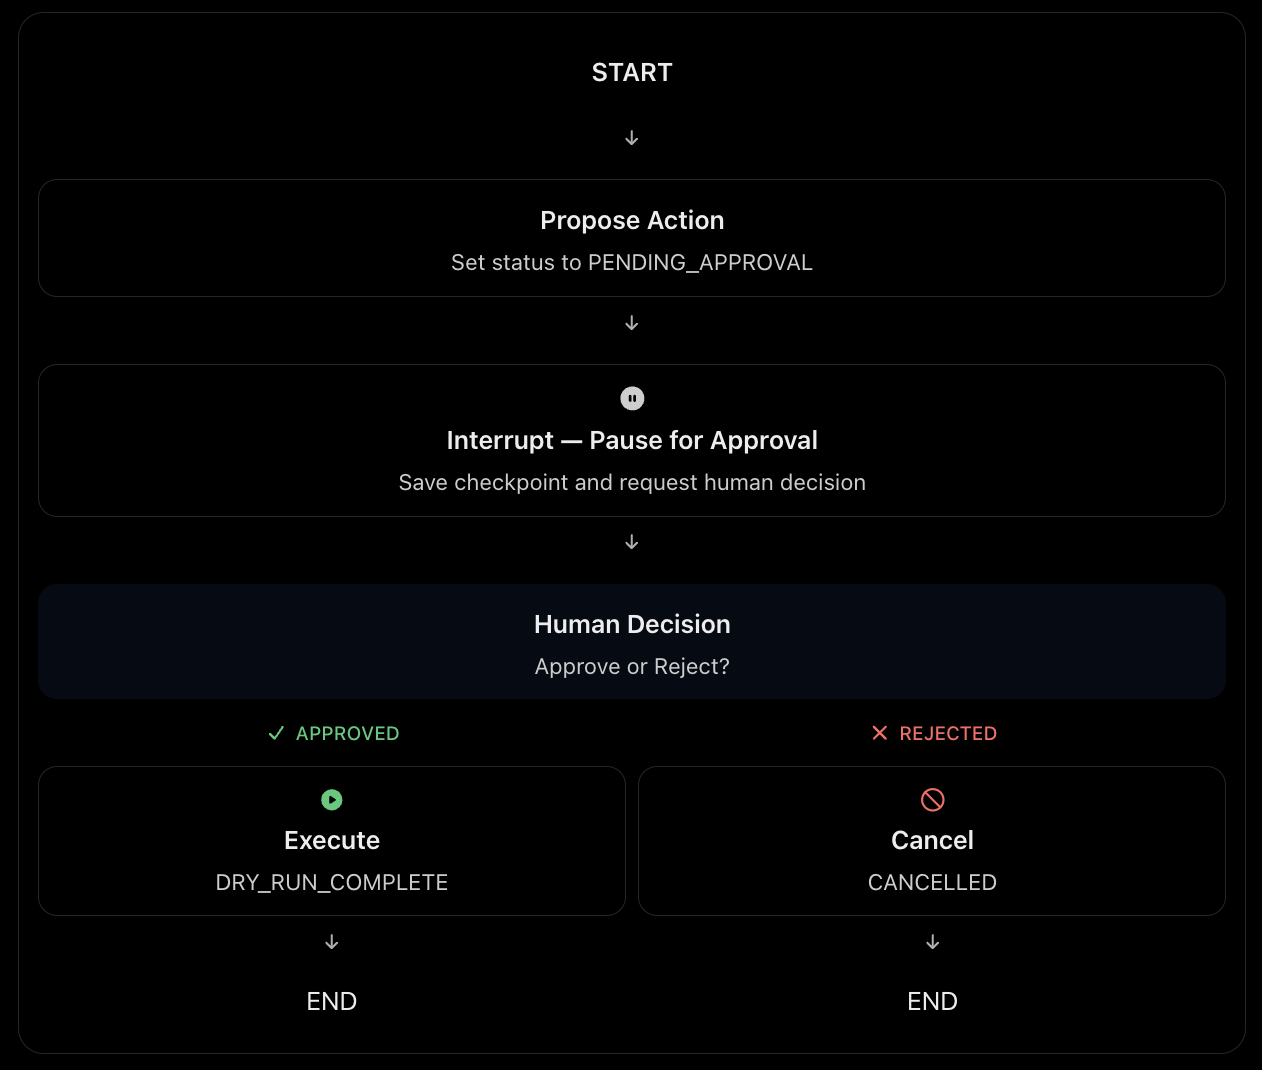

,action,requested_approval,interrupt_payload,final_status,events
0,validate a route-policy dry run,True,"{'question': 'Approve dry-run validation?', 'action': 'validate a route-policy dry run'}",DRY_RUN_COMPLETE,proposal created → human decision received → dry-run executed
1,restart a production edge router,False,"{'question': 'Approve dry-run validation?', 'action': 'restart a production edge router'}",CANCELLED,proposal created → human decision received → request cancelled



Figure D — Human approval interrupt and resume


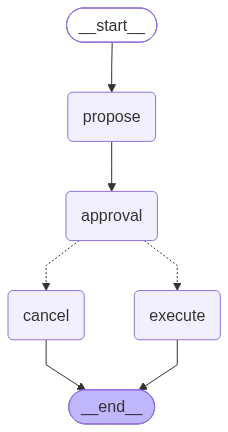

In [ ]:
class IntroApprovalState(TypedDict):
    action: str
    approved: bool | None
    status: str
    events: Annotated[list[str], operator.add]

def propose_action(state: IntroApprovalState) -> dict:
    return {"status":"PENDING_APPROVAL", "events":["proposal created"]}

def request_intro_approval(state: IntroApprovalState) -> dict:
    response = interrupt({"question":"Approve dry-run validation?", "action":state["action"]})
    return {"approved":bool(response.get("approved", False)), "events":["human decision received"]}

def intro_execute(state: IntroApprovalState) -> dict:
    return {"status":"DRY_RUN_COMPLETE", "events":["dry-run executed"]}

def intro_cancel(state: IntroApprovalState) -> dict:
    return {"status":"CANCELLED", "events":["request cancelled"]}

intro_builder = StateGraph(IntroApprovalState)
intro_builder.add_node("propose", propose_action)
intro_builder.add_node("approval", request_intro_approval)
intro_builder.add_node("execute", intro_execute)
intro_builder.add_node("cancel", intro_cancel)
intro_builder.add_edge(START, "propose")
intro_builder.add_edge("propose", "approval")
intro_builder.add_conditional_edges("approval", lambda s: "execute" if s["approved"] else "cancel", {"execute":"execute", "cancel":"cancel"})
intro_builder.add_edge("execute", END)
intro_builder.add_edge("cancel", END)
intro_graph = intro_builder.compile(checkpointer=InMemorySaver())
# InMemorySaver() is suitable for demonstrations. It keeps checkpoints in process memory, so they do not survive process restarts. Production systems typically require durable checkpoint storage i.e., a database or file system or Redis.

def run_intro_approval_example(thread_id: str, action: str, approve: bool) -> dict: # run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", True)
    config = {"configurable":{"thread_id":thread_id}}
    paused = intro_graph.invoke(
        {"action":action, "approved":None, "status":"NEW", "events":[]}, config=config,
    )
    payload = paused["__interrupt__"][0].value
    resumed = intro_graph.invoke(Command(resume={"approved":approve}), config=config)
    return {"action":action, "requested_approval":approve, "interrupt_payload":payload,
            "final_status":resumed["status"], "events":" → ".join(resumed["events"])}

intro_results = [
    run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", True),
    run_intro_approval_example("day4-intro-reject", "restart a production edge router", False),
]
display(pd.DataFrame(intro_results))
show_langgraph_figure(intro_graph, "Figure D — Human approval interrupt and resume")
assert [row["final_status"] for row in intro_results] == ["DRY_RUN_COMPLETE", "CANCELLED"]

,action,requested_approval,interrupt_payload,final_status,events
0,validate a route-policy dry run,True,"{'question': 'Approve dry-run validation?', 'action': 'validate a route-policy dry run'}",DRY_RUN_COMPLETE,proposal created → human decision received → dry-run executed
1,restart a production edge router,False,"{'question': 'Approve dry-run validation?', 'action': 'restart a production edge router'}",CANCELLED,proposal created → human decision received → request cancelled



Figure D — Human approval interrupt and resume


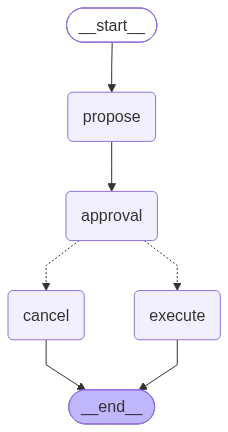

In [ ]:
class IntroApprovalState(TypedDict):
    action: str
    approved: bool | None
    status: str
    events: Annotated[list[str], operator.add]

def propose_action(state: IntroApprovalState) -> dict:
    return {"status":"PENDING_APPROVAL", "events":["proposal created"]}

def request_intro_approval(state: IntroApprovalState) -> dict:
    response = interrupt({"question":"Approve dry-run validation?", "action":state["action"]})
    return {"approved":bool(response.get("approved", False)), "events":["human decision received"]}

def intro_execute(state: IntroApprovalState) -> dict:
    return {"status":"DRY_RUN_COMPLETE", "events":["dry-run executed"]}

def intro_cancel(state: IntroApprovalState) -> dict:
    return {"status":"CANCELLED", "events":["request cancelled"]}

intro_builder = StateGraph(IntroApprovalState)
intro_builder.add_node("propose", propose_action)
intro_builder.add_node("approval", request_intro_approval)
intro_builder.add_node("execute", intro_execute)
intro_builder.add_node("cancel", intro_cancel)
intro_builder.add_edge(START, "propose")
intro_builder.add_edge("propose", "approval")
intro_builder.add_conditional_edges("approval", lambda s: "execute" if s["approved"] else "cancel", {"execute":"execute", "cancel":"cancel"})
intro_builder.add_edge("execute", END)
intro_builder.add_edge("cancel", END)
intro_graph = intro_builder.compile(checkpointer=InMemorySaver())
# InMemorySaver() is suitable for demonstrations. It keeps checkpoints in process memory, so they do not survive process restarts. Production systems typically require durable checkpoint storage i.e., a database or file system or Redis.

def run_intro_approval_example(thread_id: str, action: str, approve: bool) -> dict: # run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", True)
    config = {"configurable":{"thread_id":thread_id}}
    paused = intro_graph.invoke(
        {"action":action, "approved":None, "status":"NEW", "events":[]}, config=config,
    )
    payload = paused["__interrupt__"][0].value
    resumed = intro_graph.invoke(Command(resume={"approved":approve}), config=config)
    return {"action":action, "requested_approval":approve, "interrupt_payload":payload,
            "final_status":resumed["status"], "events":" → ".join(resumed["events"])}

intro_results = [
    run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", input("Approve dry-run validation? (y/n): ").strip().lower() == "y"), # Enter y
    run_intro_approval_example("day4-intro-reject", "restart a production edge router", input("Approve router restart? (y/n): ").strip().lower() == "y") # Enter n
]
display(pd.DataFrame(intro_results))
show_langgraph_figure(intro_graph, "Figure D — Human approval interrupt and resume")
assert [row["final_status"] for row in intro_results] == ["DRY_RUN_COMPLETE", "CANCELLED"]

### Transition to the operational lab

The next graph combines all four ideas: shared investigation state, conditional routing, a bounded evidence loop, and an explicit recommendation boundary. The node functions remain ordinary Python, which makes them individually testable.

In [14]:
class EvidenceItem(BaseModel):
    evidence_id: str
    category: Literal["incident", "monitoring", "configuration", "change", "knowledge", "topology", "policy"]
    summary: str
    source_id: str
    source_url: str
    observed_at: str | None = None
    live: bool = False


class ToolResult(BaseModel):
    tool: str
    status: Literal["OK", "UNAVAILABLE", "DENIED", "ERROR"]
    summary: str
    evidence: list[EvidenceItem] = Field(default_factory=list)
    missing_context: list[str] = Field(default_factory=list)
    retryable: bool = False


class DecisionRecord(BaseModel):
    step: int
    phase: Literal["OBSERVE", "REASON", "PLAN", "ACT", "VALIDATE", "STOP"]
    decision_summary: str
    selected_tool: str | None = None
    result_status: str | None = None


class Hypothesis(BaseModel):
    hypothesis_id: str
    statement: str
    status: Literal["SUPPORTED", "PARTIALLY_SUPPORTED", "UNSUPPORTED", "UNDETERMINED"]
    supporting_evidence: list[str] = Field(default_factory=list)
    contradicting_evidence: list[str] = Field(default_factory=list)
    validation_needed: list[str] = Field(default_factory=list)


class InvestigationState(BaseModel):
    incident_id: str
    objective: str
    environment: Literal["PUBLIC_LAB", "DEV", "TEST", "PROD"]
    step: int = 0
    status: Literal["NEW", "INVESTIGATING", "VALIDATING", "RECOMMENDING", "COMPLETE", "ESCALATED"] = "NEW"
    evidence: list[EvidenceItem] = Field(default_factory=list)
    decisions: list[DecisionRecord] = Field(default_factory=list)
    hypotheses: list[Hypothesis] = Field(default_factory=list)
    missing_context: list[str] = Field(default_factory=list)
    recommendation: str | None = None
    stop_reason: str | None = None

    def evidence_categories(self) -> set[str]:
        return {item.category for item in self.evidence}

## 2.3 Approved diagnostic tools

Each tool below is read-only and returns typed evidence. `query_monitoring` explicitly reports that no live monitoring source is connected; this is a valid observation that changes the investigation plan.

In [15]:
def evidence_from_record(record: dict[str, Any], category: str, summary: str | None = None) -> EvidenceItem:
    return EvidenceItem(
        evidence_id=f"ev-{category}-{record['doc_id']}",
        category=category,
        summary=summary or re.sub(r"\s+", " ", record["content"])[:550],
        source_id=record["doc_id"],
        source_url=record["source_url"],
        live=False,
    )


def collect_incident_evidence(query: str) -> ToolResult:
    hits = search_corpus(query, top_k=3, source_types={"historical_issue"})
    return ToolResult(
        tool="collect_incident_evidence",
        status="OK",
        summary="Retrieved genuine public L3AF project issues; these are not Walmart production incidents.",
        evidence=[evidence_from_record(hit, "incident") for hit in hits],
    )


def query_monitoring(query: str) -> ToolResult:
    hits = search_corpus(
        query,
        top_k=3,
        source_types={"configuration_repository", "configuration_standard", "historical_issue"},
    )
    return ToolResult(
        tool="query_monitoring",
        status="UNAVAILABLE",
        summary="No authorized live monitoring source is connected. Returned public monitoring-related context only.",
        evidence=[evidence_from_record(hit, "monitoring") for hit in hits],
        missing_context=["authorized live metric series", "load-error logs", "time-aligned alerts"],
    )


def inspect_configuration(section: str) -> ToolResult:
    matches = [r for r in records if r["source_type"] == "configuration_repository" and r["section"].lower() == section.lower()]
    if not matches:
        return ToolResult(tool="inspect_configuration", status="ERROR", summary=f"Unknown sample section: {section}")
    record = matches[0]
    return ToolResult(
        tool="inspect_configuration",
        status="OK",
        summary="Retrieved upstream L3AF sample configuration; it is not a Walmart deployment configuration.",
        evidence=[evidence_from_record(record, "configuration")],
    )


def check_changes(query: str) -> ToolResult:
    record = next(r for r in records if r["source_type"] == "change_records")
    changes = json.loads(record["content"])
    terms = {term.lower() for term in re.findall(r"[A-Za-z0-9_]+", query) if len(term) > 3}
    matches = [c for c in changes if terms & set(re.findall(r"[a-z0-9_]+", c["message"].lower()))][:5]
    summary = json.dumps(matches if matches else changes[:5], indent=2)
    evidence = evidence_from_record(record, "change", summary=summary[:900])
    return ToolResult(
        tool="check_changes",
        status="OK",
        summary="Returned actual public commit metadata; temporal proximity alone does not establish causation.",
        evidence=[evidence],
        missing_context=["authorized deployment/change records for the affected environment"],
    )


def retrieve_knowledge(query: str) -> ToolResult:
    hits = search_corpus(
        query,
        top_k=5,
        source_types={"production_deployment_guide", "operational_runbook", "configuration_standard", "project_readme"},
    )
    return ToolResult(
        tool="retrieve_knowledge",
        status="OK",
        summary="Retrieved public L3AF guidance and documentation.",
        evidence=[evidence_from_record(hit, "knowledge") for hit in hits],
    )


TOOL_REGISTRY: dict[str, Callable[..., ToolResult]] = {
    "collect_incident_evidence": collect_incident_evidence,
    "query_monitoring": query_monitoring,
    "inspect_configuration": inspect_configuration,
    "check_changes": check_changes,
    "retrieve_knowledge": retrieve_knowledge,
}
print("Approved tools:", sorted(TOOL_REGISTRY))

Approved tools: ['check_changes', 'collect_incident_evidence', 'inspect_configuration', 'query_monitoring', 'retrieve_knowledge']


## 2.4 Planner, action selection, and stopping rules

The LangGraph planning node has two implementations behind the same typed contract. Credential-free classroom mode uses a deterministic planner so every learner can inspect and reproduce the path. When `OPENAI_API_KEY` is present and `WAL_NET_ENABLE_LIVE_API=1`, the node uses an OpenAI Structured Output to propose the next tool. In both modes deterministic application code validates the tool name, arguments, permission, state and stopping controls; the offline result is never presented as an LLM result.

The planner stops when required evidence has been attempted and hypotheses have been validated, or when the step budget is exhausted. It never loops indefinitely.

In [16]:
class TroubleshootingGraphState(TypedDict):
    incident_id: str
    objective: str
    environment: str
    step: int
    status: str
    evidence: list[EvidenceItem]
    decisions: list[DecisionRecord]
    hypotheses: list[Hypothesis]
    missing_context: list[str]
    evidence_needed: str | None
    next_tool: str | None
    tool_arguments: dict[str, Any]
    last_tool_status: str | None
    recommendation: str | None
    stop_reason: str | None
    validation_passed: bool

REQUIRED_EVIDENCE_SEQUENCE = ["incident", "monitoring", "configuration", "change", "knowledge"]
LIVE_LANGGRAPH_LLM = bool(os.getenv("OPENAI_API_KEY")) and os.getenv("WAL_NET_ENABLE_LIVE_API") == "1"

class PlannerProposal(BaseModel):
    action: Literal[
        "collect_incident_evidence", "query_monitoring", "inspect_configuration",
        "check_changes", "retrieve_knowledge", "GENERATE_HYPOTHESES", "ESCALATE"
    ]
    query: str | None = None
    section: str | None = None
    rationale: str

def append_decision(state: TroubleshootingGraphState, phase: str, summary: str,
                    tool: str | None = None, result: str | None = None) -> list[DecisionRecord]:
    return state["decisions"] + [DecisionRecord(
        step=state["step"], phase=phase, decision_summary=summary,
        selected_tool=tool, result_status=result,
    )]

def evidence_categories_from_graph(state: TroubleshootingGraphState) -> set[str]:
    return {item.category for item in state["evidence"]}

def observe_node(state: TroubleshootingGraphState) -> dict:
    step = state["step"] + 1
    categories = sorted(evidence_categories_from_graph(state))
    updated = dict(state); updated["step"] = step
    return {
        "step":step,
        "status":"INVESTIGATING",
        "decisions":append_decision(updated, "OBSERVE", f"Evidence categories present: {categories}"),
    }

def reason_node(state: TroubleshootingGraphState) -> dict:
    categories = evidence_categories_from_graph(state)
    needed = next((category for category in REQUIRED_EVIDENCE_SEQUENCE if category not in categories), None)
    summary = f"Next evidence gap: {needed}." if needed else "Required evidence categories have been attempted."
    return {"evidence_needed":needed, "decisions":append_decision(state, "REASON", summary)}

def propose_next_plan(state: TroubleshootingGraphState) -> PlannerProposal:
    deterministic = {
        "incident":PlannerProposal(action="collect_incident_evidence", query=state["objective"], rationale="incident evidence is missing"),
        "monitoring":PlannerProposal(action="query_monitoring", query="BPFRunning metric load error polling samples", rationale="monitoring evidence is missing"),
        "configuration":PlannerProposal(action="inspect_configuration", section="web", rationale="configuration evidence is missing"),
        "change":PlannerProposal(action="check_changes", query="metric monitor BPF program load race", rationale="change evidence is missing"),
        "knowledge":PlannerProposal(action="retrieve_knowledge", query="metrics eBPF program monitoring production diagnostics", rationale="knowledge evidence is missing"),
        None:PlannerProposal(action="GENERATE_HYPOTHESES", rationale="required evidence categories were attempted"),
    }
    if not LIVE_LANGGRAPH_LLM:
        return deterministic[state["evidence_needed"]]

    from openai import OpenAI
    client = OpenAI()
    response = client.responses.parse(
        model=os.getenv("WAL_NET_MODEL", "gpt-5.6-terra"),
        reasoning={"effort":"low"},
        input=[
            {"role":"developer", "content":(
                "You are a read-only NetOps investigation planner. Select exactly one allowed action. "
                "Use the stated evidence gap, never invent tool results, and generate hypotheses only after all categories are attempted."
            )},
            {"role":"user", "content":json.dumps({
                "objective":state["objective"],
                "evidence_present":sorted(evidence_categories_from_graph(state)),
                "evidence_needed":state["evidence_needed"],
                "missing_context":sorted(set(state["missing_context"])),
                "allowed_tools":sorted(troubleshooting_contract.allowed_tools),
            })},
        ],
        text_format=PlannerProposal,
    )
    return response.output_parsed

def plan_node(state: TroubleshootingGraphState) -> dict:
    if state["step"] > troubleshooting_contract.max_steps:
        return {"next_tool":"ESCALATE", "tool_arguments":{},
                "decisions":append_decision(state, "PLAN", "Step budget exceeded; escalate.")}
    proposal = propose_next_plan(state)
    if proposal.action == "ESCALATE":
        return {"next_tool":"ESCALATE", "tool_arguments":{},
                "decisions":append_decision(state, "PLAN", proposal.rationale)}
    if proposal.action == "GENERATE_HYPOTHESES":
        return {"next_tool":None, "tool_arguments":{},
                "decisions":append_decision(state, "PLAN", proposal.rationale)}
    arguments = {"section":proposal.section} if proposal.action == "inspect_configuration" else {"query":proposal.query}
    return {"next_tool":proposal.action, "tool_arguments":arguments,
            "decisions":append_decision(state, "PLAN", f"{proposal.rationale}; arguments={arguments}.", proposal.action)}

def route_after_plan(state: TroubleshootingGraphState) -> str:
    if state["next_tool"] == "ESCALATE":
        return "escalate"
    return "act" if state["next_tool"] else "hypothesize"

def act_node(state: TroubleshootingGraphState) -> dict:
    tool_name = state["next_tool"]
    if tool_name not in troubleshooting_contract.allowed_tools:
        return {"last_tool_status":"DENIED", "stop_reason":f"Tool {tool_name} is not allowed.",
                "decisions":append_decision(state, "ACT", "Policy denied tool.", tool_name, "DENIED")}
    result = TOOL_REGISTRY[tool_name](**state["tool_arguments"])
    existing = {item.evidence_id for item in state["evidence"]}
    evidence = state["evidence"] + [item for item in result.evidence if item.evidence_id not in existing]
    return {
        "evidence":evidence,
        "missing_context":state["missing_context"] + result.missing_context,
        "last_tool_status":result.status,
        "decisions":append_decision(state, "ACT", result.summary, tool_name, result.status),
    }

def validate_observation_node(state: TroubleshootingGraphState) -> dict:
    accepted = len(state["evidence"])
    return {"decisions":append_decision(
        state, "VALIDATE", f"State now contains {accepted} sourced evidence item(s); last status={state['last_tool_status']}."
    )}

def hypothesize_node(state: TroubleshootingGraphState) -> dict:
    evidence_ids = {item.source_id for item in state["evidence"]}
    hypotheses = [
        Hypothesis(
            hypothesis_id="H1",
            statement="The published issue records a mismatch between the BPFRunning metric and a program loading error.",
            status="SUPPORTED" if "l3afd-issue-698" in evidence_ids else "UNDETERMINED",
            supporting_evidence=["l3afd-issue-698"] if "l3afd-issue-698" in evidence_ids else [],
            validation_needed=["confirm affected version and behavior in authorized live logs"],
        ),
        Hypothesis(
            hypothesis_id="H2", statement="The upstream sample polling settings caused the reported mismatch.",
            status="UNSUPPORTED", validation_needed=["sample configuration is not causal evidence", "obtain live configuration"],
        ),
        Hypothesis(
            hypothesis_id="H3", statement="A recent deployment change caused the reported issue.",
            status="UNDETERMINED", validation_needed=["obtain incident-window deployment records"],
        ),
    ]
    return {"hypotheses":hypotheses, "status":"VALIDATING",
            "decisions":append_decision(state, "REASON", "Generated falsifiable hypotheses from evidence IDs.")}

def validate_case_node(state: TroubleshootingGraphState) -> dict:
    has_incident = "incident" in evidence_categories_from_graph(state)
    citations_valid = all(item.source_id and item.source_url for item in state["evidence"])
    passed = has_incident and citations_valid and bool(state["hypotheses"])
    return {"validation_passed":passed, "decisions":append_decision(
        state, "VALIDATE", f"Evidence/hypothesis validation passed={passed}; unresolved gaps={len(set(state['missing_context']))}."
    )}

def recommend_node(state: TroubleshootingGraphState) -> dict:
    recommendation = (
        "Treat the public BPFRunning metric issue as evidence that this metric alone may be insufficient. "
        "An authorized engineer should correlate it with program load/attach logs, confirm the affected version and "
        "live configuration, and review incident-window changes before remediation."
    )
    reason = "Required public evidence attempted; recommendation produced with live-state gaps explicit."
    return {"recommendation":recommendation, "status":"COMPLETE", "stop_reason":reason,
            "decisions":append_decision(state, "STOP", reason)}

def escalate_investigation_node(state: TroubleshootingGraphState) -> dict:
    reason = state.get("stop_reason") or "Evidence validation or workflow budget failed."
    return {"status":"ESCALATED", "stop_reason":reason,
            "decisions":append_decision(state, "STOP", reason)}

troubleshooting_builder = StateGraph(TroubleshootingGraphState)
for name, fn in {
    "observe":observe_node, "reason":reason_node, "plan":plan_node, "act":act_node,
    "validate_observation":validate_observation_node, "hypothesize":hypothesize_node,
    "validate_case":validate_case_node, "recommend":recommend_node,
    "escalate":escalate_investigation_node,
}.items():
    troubleshooting_builder.add_node(name, fn)
troubleshooting_builder.add_edge(START, "observe")
troubleshooting_builder.add_edge("observe", "reason")
troubleshooting_builder.add_edge("reason", "plan")
troubleshooting_builder.add_conditional_edges("plan", route_after_plan,
    {"act":"act", "hypothesize":"hypothesize", "escalate":"escalate"})
troubleshooting_builder.add_edge("act", "validate_observation")
troubleshooting_builder.add_edge("validate_observation", "observe")
troubleshooting_builder.add_edge("hypothesize", "validate_case")
troubleshooting_builder.add_conditional_edges("validate_case",
    lambda s: "recommend" if s["validation_passed"] else "escalate",
    {"recommend":"recommend", "escalate":"escalate"})
troubleshooting_builder.add_edge("recommend", END)
troubleshooting_builder.add_edge("escalate", END)
troubleshooting_graph = troubleshooting_builder.compile()

print("Troubleshooting graph nodes:", sorted(troubleshooting_graph.get_graph().nodes))
print("Troubleshooting graph edges:", len(troubleshooting_graph.get_graph().edges))
print("Planner mode:", "OpenAI structured planner" if LIVE_LANGGRAPH_LLM else "deterministic classroom planner")

Troubleshooting graph nodes: ['__end__', '__start__', 'act', 'escalate', 'hypothesize', 'observe', 'plan', 'reason', 'recommend', 'validate_case', 'validate_observation']
Troubleshooting graph edges: 13
Planner mode: deterministic classroom planner



Mermaid Figure — Public L3AF Evidence Investigator workflow


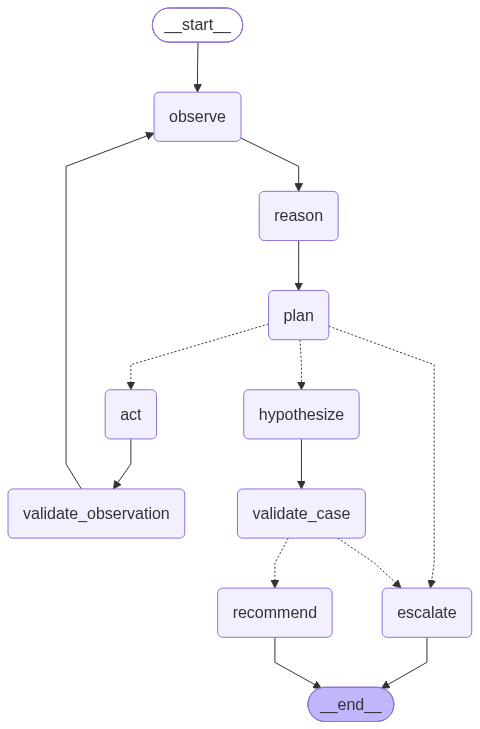

In [17]:
show_langgraph_figure(troubleshooting_graph, "Mermaid Figure — Public L3AF Evidence Investigator workflow")


# Hands-on Lab 8 — Build an AI Network Troubleshooting Agent

## Mission

Build a tool-enabled agent that autonomously determines:

- what evidence is required;
- which diagnostic tool to invoke;
- what additional context is missing;
- which hypotheses are supported;
- what action should be recommended.

### Public issue scenario

Investigate L3AF issue **#698**, which reports that `l3afd_BPFRunning` can report true while a program-loading error occurs. The lab must not infer a Walmart production incident or query a live environment.

In [19]:
class AgentContract(BaseModel):
    model_config = ConfigDict(extra="forbid")

    name: str
    goal: str
    success_criteria: list[str]
    allowed_tools: set[str]
    prohibited_actions: list[str]
    max_steps: int = Field(ge=1, le=20)
    requires_citations: bool = True
    human_gate_before_write: bool = True

troubleshooting_contract = AgentContract(
    name="Public L3AF Evidence Investigator",
    goal="Produce a source-attributed investigation of a public L3AF issue without claiming live access.",
    success_criteria=[
        "required evidence categories are attempted",
        "hypotheses are labeled by support status",
        "missing live context is explicit",
        "recommendation contains no unauthorized execution",
    ],
    allowed_tools={
        "collect_incident_evidence",
        "query_monitoring",
        "inspect_configuration",
        "check_changes",
        "retrieve_knowledge",
    },
    prohibited_actions=["execute shell commands", "change infrastructure", "invent live telemetry"],
    max_steps=10,
)
print(troubleshooting_contract.model_dump_json(indent=2))

{
  "name": "Public L3AF Evidence Investigator",
  "goal": "Produce a source-attributed investigation of a public L3AF issue without claiming live access.",
  "success_criteria": [
    "required evidence categories are attempted",
    "hypotheses are labeled by support status",
    "missing live context is explicit",
    "recommendation contains no unauthorized execution"
  ],
  "allowed_tools": [
    "check_changes",
    "inspect_configuration",
    "retrieve_knowledge",
    "collect_incident_evidence",
    "query_monitoring"
  ],
  "prohibited_actions": [
    "execute shell commands",
    "change infrastructure",
    "invent live telemetry"
  ],
  "max_steps": 10,
  "requires_citations": true,
  "human_gate_before_write": true
}


Status: COMPLETE
Stop reason: Required public evidence attempted; recommendation produced with live-state gaps explicit.
Recommendation: Treat the public BPFRunning metric issue as evidence that this metric alone may be insufficient. An authorized engineer should correlate it with program load/attach logs, confirm the affected version and live configuration, and review incident-window changes before remediation.


,scenario,status,steps,evidence_items,hypotheses,stop_reason
0,normal evidence budget,COMPLETE,6,13,3,Required public evidence attempted; recommendation produced with live-state gaps explicit.
1,budget already exhausted,ESCALATED,11,0,0,Evidence validation or workflow budget failed.



Figure E — Lab 8 troubleshooting agent


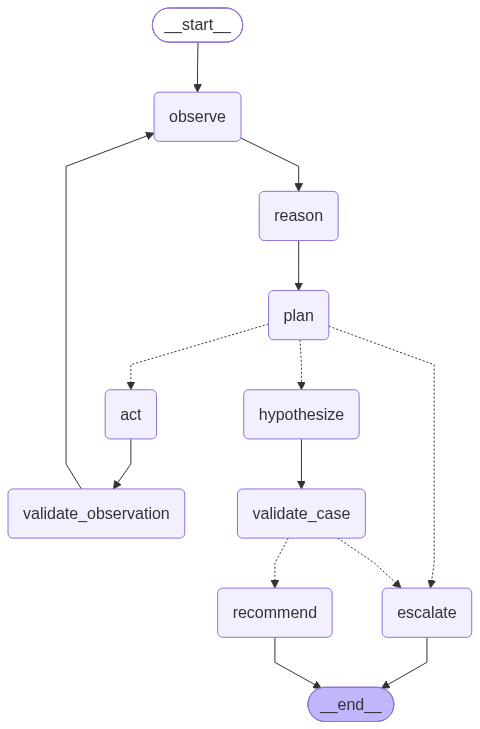

In [20]:
lab8_initial: TroubleshootingGraphState = {
    "incident_id":"PUBLIC-L3AF-ISSUE-698",
    "objective":"Investigate the public report that l3afd_BPFRunning is true while an eBPF program loading error occurs.",
    "environment":"PUBLIC_LAB",
    "step":0, "status":"NEW", "evidence":[], "decisions":[], "hypotheses":[],
    "missing_context":[], "evidence_needed":None, "next_tool":None, "tool_arguments":{},
    "last_tool_status":None, "recommendation":None, "stop_reason":None,
    "validation_passed":False,
}
lab8_graph_result = troubleshooting_graph.invoke(lab8_initial, config={"recursion_limit":50})
lab8_result = InvestigationState(
    incident_id=lab8_graph_result["incident_id"],
    objective=lab8_graph_result["objective"],
    environment=lab8_graph_result["environment"],
    step=lab8_graph_result["step"],
    status=lab8_graph_result["status"],
    evidence=lab8_graph_result["evidence"],
    decisions=lab8_graph_result["decisions"],
    hypotheses=lab8_graph_result["hypotheses"],
    missing_context=lab8_graph_result["missing_context"],
    recommendation=lab8_graph_result["recommendation"],
    stop_reason=lab8_graph_result["stop_reason"],
)

print("Status:", lab8_result.status)
print("Stop reason:", lab8_result.stop_reason)
print("Recommendation:", lab8_result.recommendation)

budget_limited_initial = dict(lab8_initial)
budget_limited_initial.update({"incident_id":"PUBLIC-L3AF-BUDGET-DEMO", "step":10})
budget_limited_graph_result = troubleshooting_graph.invoke(
    budget_limited_initial, config={"recursion_limit":10}
)

lab8_scenario_report = pd.DataFrame([
    {
        "scenario":"normal evidence budget",
        "status":lab8_graph_result["status"],
        "steps":lab8_graph_result["step"],
        "evidence_items":len(lab8_graph_result["evidence"]),
        "hypotheses":len(lab8_graph_result["hypotheses"]),
        "stop_reason":lab8_graph_result["stop_reason"],
    },
    {
        "scenario":"budget already exhausted",
        "status":budget_limited_graph_result["status"],
        "steps":budget_limited_graph_result["step"],
        "evidence_items":len(budget_limited_graph_result["evidence"]),
        "hypotheses":len(budget_limited_graph_result["hypotheses"]),
        "stop_reason":budget_limited_graph_result["stop_reason"],
    },
])
display(lab8_scenario_report)
show_langgraph_figure(troubleshooting_graph, "Figure E — Lab 8 troubleshooting agent")
assert set(lab8_scenario_report.status) == {"COMPLETE", "ESCALATED"}

In [22]:
decision_df = pd.DataFrame([item.model_dump() for item in lab8_result.decisions])
evidence_df = pd.DataFrame([item.model_dump() for item in lab8_result.evidence])
hypothesis_df = pd.DataFrame([item.model_dump() for item in lab8_result.hypotheses])

display(decision_df)
display(evidence_df[["category", "source_id", "live", "summary", "source_url"]])
display(hypothesis_df)
print("Missing live context:", sorted(set(lab8_result.missing_context)))

,step,phase,decision_summary,selected_tool,result_status
0,1,OBSERVE,Evidence categories present: [],NaN,NaN
1,1,REASON,Next evidence gap: incident.,NaN,NaN
2,1,PLAN,incident evidence is missing; arguments={'query': 'Investigate the public report that l3afd_BPFRunning is true while...,collect_incident_evidence,NaN
3,1,ACT,Retrieved genuine public L3AF project issues; these are not Walmart production incidents.,collect_incident_evidence,OK
4,1,VALIDATE,State now contains 3 sourced evidence item(s); last status=OK.,NaN,NaN
5,2,OBSERVE,Evidence categories present: ['incident'],NaN,NaN
6,2,REASON,Next evidence gap: monitoring.,NaN,NaN
7,2,PLAN,monitoring evidence is missing; arguments={'query': 'BPFRunning metric load error polling samples'}.,query_monitoring,NaN
8,2,ACT,No authorized live monitoring source is connected. Returned public monitoring-related context only.,query_monitoring,UNAVAILABLE
9,2,VALIDATE,State now contains 6 sourced evidence item(s); last status=UNAVAILABLE.,NaN,NaN


,category,source_id,live,summary,source_url
0,incident,l3afd-issue-698,False,"{ ""number"": 698, ""state"": ""closed"", ""title"": ""l3afd_BPFRunning metric reports true incase of ebpf_program loading er...",https://github.com/l3af-project/l3afd/issues/698
1,incident,l3afd-issue-523,False,"{ ""number"": 523, ""state"": ""closed"", ""title"": ""Add metrics to count ebpf program loading failure errors"", ""labels"": [...",https://github.com/l3af-project/l3afd/issues/523
2,incident,l3afd-issue-637,False,"{ ""number"": 637, ""state"": ""closed"", ""title"": ""Remove stale metric reporting on eBPF program unload"", ""labels"": [], ""...",https://github.com/l3af-project/l3afd/issues/637
3,monitoring,l3afd-config-web,False,"{ ""metrics-addr"": ""localhost:8898"", ""ebpf-poll-interval"": ""30s"", ""n-metric-samples"": ""20"" }",https://github.com/l3af-project/l3afd/blob/main/config/l3afd.cfg
4,monitoring,configuration_standard-05,False,| FieldName | Default | Description | Required | |--------------------| ------------- | --------------- |----------|...,https://github.com/l3af-project/l3afd/blob/main/docs/configdoc.md
5,monitoring,l3afd-issue-698,False,"{ ""number"": 698, ""state"": ""closed"", ""title"": ""l3afd_BPFRunning metric reports true incase of ebpf_program loading er...",https://github.com/l3af-project/l3afd/issues/698
6,configuration,l3afd-config-web,False,"{ ""metrics-addr"": ""localhost:8898"", ""ebpf-poll-interval"": ""30s"", ""n-metric-samples"": ""20"" }",https://github.com/l3af-project/l3afd/blob/main/config/l3afd.cfg
7,change,l3afd-recent-public-changes,False,"[\n {\n ""sha"": ""7d5dbf6f8ad32d4008ac659d9bd860e3fa101979"",\n ""date"": ""2026-07-23T06:51:22Z"",\n ""author"": ""...",https://github.com/l3af-project/l3afd/commits/main
8,knowledge,production_deployment_guide-02,False,This guide lists recommendations on how to run l3afd in a production environment. Please see [l3afd.cfg](../config/l...,https://github.com/l3af-project/l3afd/blob/main/docs/prod-deploy-guide.md
9,knowledge,configuration_standard-05,False,| FieldName | Default | Description | Required | |--------------------| ------------- | --------------- |----------|...,https://github.com/l3af-project/l3afd/blob/main/docs/configdoc.md


,hypothesis_id,statement,status,supporting_evidence,contradicting_evidence,validation_needed
0,H1,The published issue records a mismatch between the BPFRunning metric and a program loading error.,SUPPORTED,[l3afd-issue-698],[],[confirm affected version and behavior in authorized live logs]
1,H2,The upstream sample polling settings caused the reported mismatch.,UNSUPPORTED,[],[],"[sample configuration is not causal evidence, obtain live configuration]"
2,H3,A recent deployment change caused the reported issue.,UNDETERMINED,[],[],[obtain incident-window deployment records]


Missing live context: ['authorized deployment/change records for the affected environment', 'authorized live metric series', 'load-error logs', 'time-aligned alerts']


# Happy Learning